In [41]:
from math import log
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import multivariate_normal

seed=42

def myRandom():
    global seed
    a = 1664525
    c = 1013904223
    m = 2**32
    seed=(a*seed+c)%m
    return seed/m

def myUniform(a,b):
    return a+(b-a)*myRandom()

# Generate Gaussian random values using Marsaglia polar method
def gaussian(mu, sigma, n):
    g = []
    while len(g) < n:
        u1 = myUniform(-1, 1)
        u2 = myUniform(-1, 1)
        s = u1 * u1 + u2 * u2
        if s > 0 and s < 1:
            k = (-2 * log(s) / s) ** 0.5
            x = u1 * k
            y = u2 * k
            g.append(mu + sigma * x)
            if len(g) < n:
                g.append(mu + sigma * y)
    return g

Data generation with isotropic, diagonal and full covariance cases:

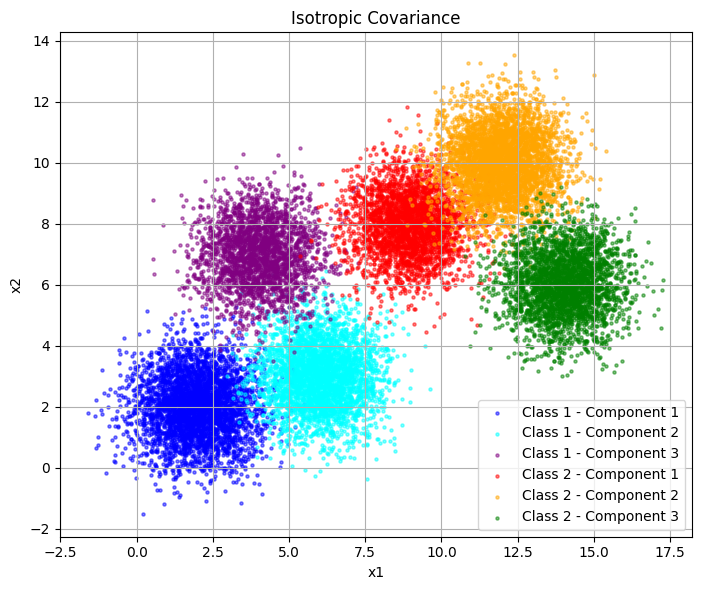

Class 1 points: 10000
Class 2 points: 10000


In [42]:
n = 10000
case = 1  # 1 = Isotropic, 2 = Diagonal, 3 = Full
# Three Gaussian components for each class
means_class1 = [[2, 2], [6, 3], [4, 7]]
means_class2 = [[9, 8], [12, 10], [14, 6]]
# Mixture weights
weights_class1 = [0.40, 0.35, 0.25]
weights_class2 = [0.30, 0.40, 0.30]
# Covariance matrices
isotropic_cov = np.array([
    [1, 0],
    [0, 1]
])
diagonal_cov = np.array([
    [4, 0],
    [0, 1]
])
full_cov = np.array([
    [2, 0.8],
    [0.8, 1.5]
])
# 1. Isotropic covariance
def generate_isotropic(mu, sigma, N):
    x1 = gaussian(mu[0], sigma, N)
    x2 = gaussian(mu[1], sigma, N)
    return np.column_stack((x1, x2))
# 2. Diagonal covariance
def generate_diagonal(mu, sigma_x, sigma_y, N):
    x1 = gaussian(mu[0], sigma_x, N)
    x2 = gaussian(mu[1], sigma_y, N)
    return np.column_stack((x1, x2))
# 3. Full covariance
def generate_full(mu, cov, N):
    Z = np.column_stack((
        gaussian(0, 1, N),
        gaussian(0, 1, N)
    ))
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    Lambda_sqrt = np.diag(np.sqrt(eigenvalues))
    C_sqrt = eigenvectors @ Lambda_sqrt @ eigenvectors.T
    return Z @ C_sqrt.T + np.array(mu)
# Generate data using threshold logic
def generate_data(n, weights, means, case):
    components = [[], [], []]
    for _ in range(n):
        u = myRandom()
        if u < weights[0]:
            component = 0
        elif u < weights[0] + weights[1]:
            component = 1
        else:
            component = 2
        components[component].append(1)
    if case == 1:
        c1 = generate_isotropic(
            means[0], 1, len(components[0]))
        c2 = generate_isotropic(
            means[1], 1, len(components[1]))
        c3 = generate_isotropic(
            means[2], 1, len(components[2]))
    elif case == 2:
        c1 = generate_diagonal(
            means[0], 2, 1, len(components[0]))
        c2 = generate_diagonal(
            means[1], 2, 1, len(components[1]))
        c3 = generate_diagonal(
            means[2], 2, 1, len(components[2]))
    elif case == 3:
        c1 = generate_full(
            means[0], full_cov, len(components[0]))
        c2 = generate_full(
            means[1], full_cov, len(components[1]))
        c3 = generate_full(
            means[2], full_cov, len(components[2]))
    else:
        raise ValueError("case must be 1, 2, or 3")
    return c1, c2, c3
# Select covariance type
if case == 1:
    title = "Isotropic Covariance"
elif case == 2:
    title = "Diagonal Covariance"
elif case == 3:
    title = "Full Covariance"
else:
    raise ValueError("case must be 1, 2, or 3")
# Generate three components for each class
c1_component1, c1_component2, c1_component3 = generate_data(
    n, weights_class1, means_class1, case
)
c2_component1, c2_component2, c2_component3 = generate_data(
    n, weights_class2, means_class2, case
)
# Combine components of each class
class1 = np.vstack((
    c1_component1, c1_component2, c1_component3
))
class2 = np.vstack((
    c2_component1, c2_component2, c2_component3
))
# Plot all components
plt.figure(figsize=(9, 6))
plt.scatter(c1_component1[:, 0], c1_component1[:, 1],
            s=5, alpha=0.5, color="blue",
            label="Class 1 - Component 1")
plt.scatter(c1_component2[:, 0], c1_component2[:, 1],
            s=5, alpha=0.5, color="cyan",
            label="Class 1 - Component 2")
plt.scatter(c1_component3[:, 0], c1_component3[:, 1],
            s=5, alpha=0.5, color="purple",
            label="Class 1 - Component 3")
plt.scatter(c2_component1[:, 0], c2_component1[:, 1],
            s=5, alpha=0.5, color="red",
            label="Class 2 - Component 1")
plt.scatter(c2_component2[:, 0], c2_component2[:, 1],
            s=5, alpha=0.5, color="orange",
            label="Class 2 - Component 2")
plt.scatter(c2_component3[:, 0], c2_component3[:, 1],
            s=5, alpha=0.5, color="green",
            label="Class 2 - Component 3")

plt.axis("equal")
plt.gca().set_aspect("equal", adjustable="box")
plt.title(title)
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
print("Class 1 points:", len(class1))
print("Class 2 points:", len(class2))

In [43]:
# Split data into training and testing sets
def split_data(data):
    indices = np.random.permutation(len(data))
    split_index = int(0.8 * len(data))
    train = data[indices[:split_index]]
    test = data[indices[split_index:]]
    return train, test
train1, test1 = split_data(class1)
train2, test2 = split_data(class2)

In [44]:
# K-means algorithm
def kmeans(data, K, max_iter=100):
    # Step 1: Randomly initialize K centroids
    indices = np.random.choice(len(data), K, replace=False)
    centroids = data[indices].copy()
    for iteration in range(max_iter):
        # Step 2: Assign each point to the nearest centroid
        distances = np.zeros((len(data), K))
        for k in range(K):
            distances[:, k] = np.sum(
                (data - centroids[k]) ** 2, axis=1
            )
        labels = np.argmin(distances, axis=1)
        # Step 3: Reestimate the means
        new_centroids = centroids.copy()
        for k in range(K):
            points = data[labels == k]
            if len(points) > 0:
                new_centroids[k] = np.mean(points, axis=0)
        # Step 4: Repeat until convergence
        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break
        centroids = new_centroids
    # Reassign points using the final centroids
    distances = np.zeros((len(data), K))
    for k in range(K):
        distances[:, k] = np.sum(
            (data - centroids[k]) ** 2, axis=1
        )
    labels = np.argmin(distances, axis=1)
    # Calculate distortion
    distortion = 0
    for n in range(len(data)):
       for k in range(K):
          gamma_nk = 1 if labels[n] == k else 0
          distortion += gamma_nk * np.sum(
          (data[n] - centroids[k]) ** 2
          )
    return centroids, labels, distortion
# Apply K-means to the training data of each class
K = 3
centroids1, labels1, distortion1 = kmeans(train1, K)
centroids2, labels2, distortion2 = kmeans(train2, K)
# Display results
print("CLASS 1")
print("Centroids:\n", centroids1)
print("Distortion:", distortion1)
print("\nCLASS 2")
print("Centroids:\n", centroids2)
print("Distortion:", distortion2)

CLASS 1
Centroids:
 [[6.0129085  2.98411826]
 [1.96175224 1.97940986]
 [4.01276358 6.98453811]]
Distortion: 15618.665523796724

CLASS 2
Centroids:
 [[ 8.94894524  7.99392978]
 [12.00865731 10.0611129 ]
 [14.02571964  6.04009155]]
Distortion: 15051.393982012693


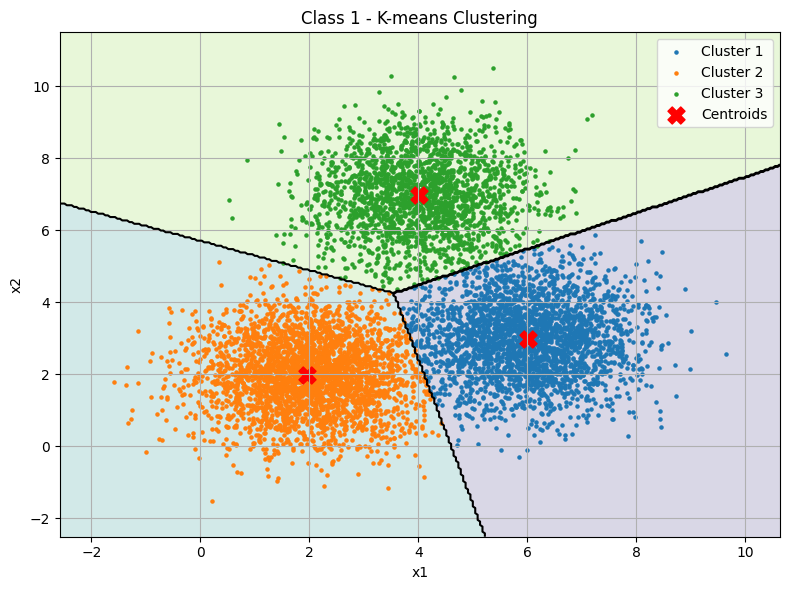

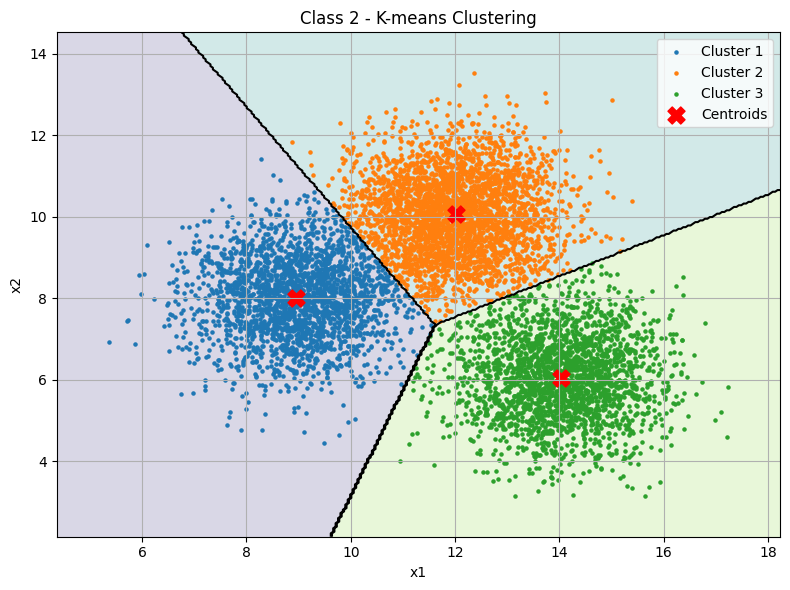

In [45]:
# Plot K-means clusters and boundaries
def plot_clusters(data, centroids, labels, title):

    # Define plotting range
    x_min = data[:, 0].min() - 1
    x_max = data[:, 0].max() + 1
    y_min = data[:, 1].min() - 1
    y_max = data[:, 1].max() + 1

    # Create grid
    x_values = np.linspace(x_min, x_max, 300)
    y_values = np.linspace(y_min, y_max, 300)
    X_grid, Y_grid = np.meshgrid(x_values, y_values)

    grid_points = np.column_stack(
        (X_grid.ravel(), Y_grid.ravel())
    )

    # Assign grid points to nearest centroid
    distances = np.zeros((len(grid_points), len(centroids)))

    for k in range(len(centroids)):
        distances[:, k] = np.sum(
            (grid_points - centroids[k]) ** 2, axis=1
        )

    grid_predictions = np.argmin(distances, axis=1)
    decision_grid = grid_predictions.reshape(X_grid.shape)

    # Plot cluster regions
    plt.figure(figsize=(8, 6))

    plt.contourf(
        X_grid, Y_grid, decision_grid,
        levels=np.arange(len(centroids) + 1) - 0.5,
        alpha=0.2
    )

    # Draw boundaries between clusters
    plt.contour(
        X_grid, Y_grid, decision_grid,
        levels=np.arange(len(centroids) - 1) + 0.5,
        colors="black"
    )

    # Plot data points belonging to each cluster
    for k in range(len(centroids)):
        points = data[labels == k]

        plt.scatter(
            points[:, 0], points[:, 1],
            s=5, label="Cluster " + str(k + 1)
        )

    # Plot centroids
    plt.scatter(
        centroids[:, 0], centroids[:, 1],
        color="red", marker="X", s=150,
        label="Centroids"
    )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# Plot Class 1
plot_clusters(
    train1, centroids1, labels1,
    "Class 1 - K-means Clustering"
)

# Plot Class 2
plot_clusters(
    train2, centroids2, labels2,
    "Class 2 - K-means Clustering"
)

In [46]:

# Predict class for each test sample
def classify_kmeans(data, centroids1, centroids2):

    predictions = []

    for x in data:
        d1 = np.min(np.sum((centroids1 - x) ** 2, axis=1))
        d2 = np.min(np.sum((centroids2 - x) ** 2, axis=1))

        if d1 < d2:
            predictions.append(1)
        else:
            predictions.append(2)

    return np.array(predictions)


pred_test1 = classify_kmeans(test1, centroids1, centroids2)
pred_test2 = classify_kmeans(test2, centroids1, centroids2)

# True labels
true_test1 = np.ones(len(test1), dtype=int)
true_test2 = np.full(len(test2), 2, dtype=int)

# Combine predictions and true labels
predicted_labels = np.concatenate((pred_test1, pred_test2))
true_labels = np.concatenate((true_test1, true_test2))

# Calculate accuracy
correct = np.sum(predicted_labels == true_labels)
total = len(true_labels)
accuracy = (correct / total) * 100

print("\nOverall Classification Results")
print("Correct predictions:", correct)
print("Total test samples:", total)
print("Accuracy:", accuracy, "%")



Overall Classification Results
Correct predictions: 3992
Total test samples: 4000
Accuracy: 99.8 %


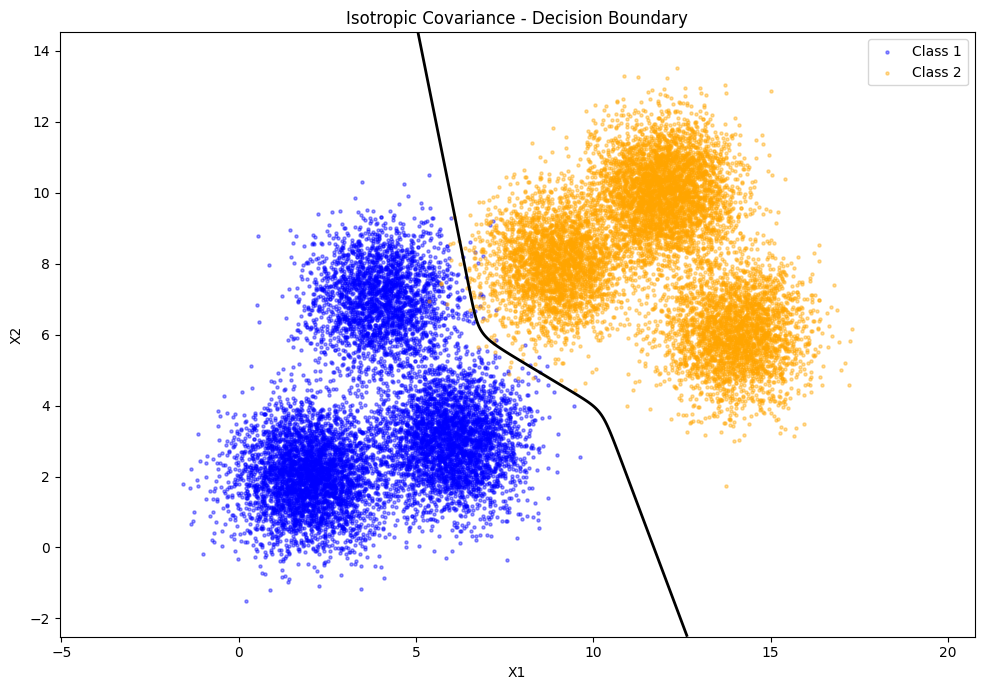

In [50]:
if case == 1:
    cov = isotropic_cov
elif case == 2:
    cov = diagonal_cov
else:
    cov = full_cov

def discriminant(X, Y, mu, cov):
    points = np.column_stack((X.ravel(), Y.ravel()))
    diff = points - np.array(mu)
    inv_cov = np.linalg.inv(cov)
    sign, log_det = np.linalg.slogdet(cov)
    exponent = np.sum((diff @ inv_cov) * diff, axis=1)
    d = 2
    return (-0.5 * (
        d * np.log(2 * np.pi) + log_det + exponent
    )).reshape(X.shape)

def mixture_discriminant(X, Y, means, weights, cov):
    density = np.zeros(X.shape)
    for k in range(3):
        g = discriminant(X, Y, means[k], cov)
        density += weights[k] * np.exp(g)
    return np.log(density + 1e-300)
x_min = min(class1[:, 0].min(), class2[:, 0].min()) - 1
x_max = max(class1[:, 0].max(), class2[:, 0].max()) + 1
y_min = min(class1[:, 1].min(), class2[:, 1].min()) - 1
y_max = max(class1[:, 1].max(), class2[:, 1].max()) + 1
x = np.linspace(x_min, x_max, 400)
y = np.linspace(y_min, y_max, 400)
X, Y = np.meshgrid(x, y)
G1 = mixture_discriminant(
    X, Y, means_class1, weights_class1, cov
)
G2 = mixture_discriminant(
    X, Y, means_class2, weights_class2, cov
)
D = G1 - G2
plt.figure(figsize=(10, 7))
plt.scatter(class1[:, 0], class1[:, 1],
            s=5, alpha=0.4, color="blue", label="Class 1")
plt.scatter(class2[:, 0], class2[:, 1],
            s=5, alpha=0.4, color="orange", label="Class 2")
plt.contour(X, Y, D, levels=[0],
            colors="black", linewidths=2)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title(title + " - Decision Boundary")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.show()